# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot wind rose for each pattern for the four villages
- Lowest Level (~60m) U and V
- Calculate daily wind speed and direction from this that go into wind rose

**Notebook by Alice DuVivier - July 2026**

In [2]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
from datetime import timedelta
from itertools import product
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick
import metpy.calc as mpcalc
from metpy.calc import wind_speed
from metpy.calc import wind_direction
from metpy.units import units
from windrose import WindroseAxes
import math

## Set village and node of choice

In [3]:
# set paired lists name and node of interest
village_names = ['Nome','Savoonga','Shishmaref','Unalakleet']
village_lats =  [64.501, 63.694, 66.257, 63.879]
village_lons =  [-165.406, -170.479, -166.072, -160.790]

# set xloc and yloc values - determined from another notebook finding nearest atmospheric point that is over mostly ocean
village_xlocs = [57,55,65,55]
village_ylocs = [98,78,95,115]

In [4]:
# set node info - '2a' or '2b'
som_nodes = ['0a','0b','0c','1a','1b','1c','2a','2b','2c']

In [189]:
## MANUAL CHANGING REQUIRED HERE ##
# select which node to plot (0-8)
s = 8

## Load data
- not identical to training data so we can see larger area patterns

In [190]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_single_node/'

In [191]:
# choose data - load zonal wind first
var_in = 'UBOT'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+som_nodes[s]+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
uwnd = data

In [192]:
# choose data - load meridional wind next
var_in = 'VBOT'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+som_nodes[s]+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
vwnd = data

In [193]:
# set lat/lon
lat1d = ds.lat
lon1d = ds.lon

In [194]:
units = ds.units

## Get data at villages to get distributions

In [195]:
n = 0

# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# get lat and lon for this village - note longitudes must be in 0-360, so must convert longitudes
lat_village = village_lats[n]
lon_village = village_lons[n] + 360

# read in xloc and yloc for this village
xloc = village_xlocs[n]
yloc = village_ylocs[n]

# get values on CESM grid
lat_grid = lat1d.isel(lat=xloc).values
lon_grid = lon1d.isel(lon=yloc).values

# Check how close these are to the latitude and longitude of the village
print('Real location: '+str(lat_village)+','+str(lon_village))
print('grid point: '+str(lat_grid)+','+str(lon_grid))

# All times
uwnd_village = uwnd.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
uwnd_village_0 = uwnd_village.isel(lat=0,lon=0)
vwnd_village = vwnd.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
vwnd_village_0 = vwnd_village.isel(lat=0,lon=0)

Nome
Real location: 64.501,194.594
grid point: 64.375,194.625


In [196]:
n = 1

# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# get lat and lon for this village - note longitudes must be in 0-360, so must convert longitudes
lat_village = village_lats[n]
lon_village = village_lons[n] + 360

# read in xloc and yloc for this village
xloc = village_xlocs[n]
yloc = village_ylocs[n]

# get values on CESM grid
lat_grid = lat1d.isel(lat=xloc).values
lon_grid = lon1d.isel(lon=yloc).values

# Check how close these are to the latitude and longitude of the village
print('Real location: '+str(lat_village)+','+str(lon_village))
print('grid point: '+str(lat_grid)+','+str(lon_grid))

# All times
uwnd_village = uwnd.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
uwnd_village_1 = uwnd_village.isel(lat=0,lon=0)
vwnd_village = vwnd.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
vwnd_village_1 = vwnd_village.isel(lat=0,lon=0)

Savoonga
Real location: 63.694,189.521
grid point: 63.875,189.625


In [197]:
n = 2

# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# get lat and lon for this village - note longitudes must be in 0-360, so must convert longitudes
lat_village = village_lats[n]
lon_village = village_lons[n] + 360

# read in xloc and yloc for this village
xloc = village_xlocs[n]
yloc = village_ylocs[n]

# get values on CESM grid
lat_grid = lat1d.isel(lat=xloc).values
lon_grid = lon1d.isel(lon=yloc).values

# Check how close these are to the latitude and longitude of the village
print('Real location: '+str(lat_village)+','+str(lon_village))
print('grid point: '+str(lat_grid)+','+str(lon_grid))

# All times
uwnd_village = uwnd.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
uwnd_village_2 = uwnd_village.isel(lat=0,lon=0)
vwnd_village = vwnd.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
vwnd_village_2 = vwnd_village.isel(lat=0,lon=0)

Shishmaref
Real location: 66.257,193.928
grid point: 66.375,193.875


In [198]:
n = 3

# set the village information above to pair with the individual nodes, print them here for sanity
print(village_names[n])

# get lat and lon for this village - note longitudes must be in 0-360, so must convert longitudes
lat_village = village_lats[n]
lon_village = village_lons[n] + 360

# read in xloc and yloc for this village
xloc = village_xlocs[n]
yloc = village_ylocs[n]

# get values on CESM grid
lat_grid = lat1d.isel(lat=xloc).values
lon_grid = lon1d.isel(lon=yloc).values

# Check how close these are to the latitude and longitude of the village
print('Real location: '+str(lat_village)+','+str(lon_village))
print('grid point: '+str(lat_grid)+','+str(lon_grid))

# All times
uwnd_village = uwnd.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
uwnd_village_3 = uwnd_village.isel(lat=0,lon=0)
vwnd_village = vwnd.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
vwnd_village_3 = vwnd_village.isel(lat=0,lon=0)

Unalakleet
Real location: 63.879,199.21
grid point: 63.875,198.875


## Calculate wind speed and direction

In [199]:
import metpy.calc as mpcalc
from metpy.calc import wind_speed
from metpy.calc import wind_direction
from metpy.units import units

In [200]:
# First village
utmp = uwnd_village_0.to_numpy()
vtmp = vwnd_village_0.to_numpy()

utmp = utmp * (units.meter / units.second)
vtmp = vtmp * (units.meter / units.second)
ws_array = wind_speed(utmp,vtmp)
wd_array = wind_direction(utmp,vtmp)

# convert to xarray for later plotting
ws_all_0 = xr.DataArray(ws_array,dims=('dates'))
wd_all_0 = xr.DataArray(wd_array,dims=('dates'))

In [201]:
# Second village
utmp = uwnd_village_1.to_numpy()
vtmp = vwnd_village_1.to_numpy()

utmp = utmp * (units.meter / units.second)
vtmp = vtmp * (units.meter / units.second)
ws_array = wind_speed(utmp,vtmp)
wd_array = wind_direction(utmp,vtmp)

# convert to xarray for later plotting
ws_all_1 = xr.DataArray(ws_array,dims=('dates'))
wd_all_1 = xr.DataArray(wd_array,dims=('dates'))

In [202]:
# Third village
utmp = uwnd_village_2.to_numpy()
vtmp = vwnd_village_2.to_numpy()

utmp = utmp * (units.meter / units.second)
vtmp = vtmp * (units.meter / units.second)
ws_array = wind_speed(utmp,vtmp)
wd_array = wind_direction(utmp,vtmp)

# convert to xarray for later plotting
ws_all_2 = xr.DataArray(ws_array,dims=('dates'))
wd_all_2 = xr.DataArray(wd_array,dims=('dates'))

In [203]:
# Fourth village
utmp = uwnd_village_3.to_numpy()
vtmp = vwnd_village_3.to_numpy()

utmp = utmp * (units.meter / units.second)
vtmp = vtmp * (units.meter / units.second)
ws_array = wind_speed(utmp,vtmp)
wd_array = wind_direction(utmp,vtmp)

# convert to xarray for later plotting
ws_all_3 = xr.DataArray(ws_array,dims=('dates'))
wd_all_3 = xr.DataArray(wd_array,dims=('dates'))

## Plot wind data at each village

In [204]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

In [205]:
# define a function for windrose colormap
def truncate_colormap(color, minval=0.0, maxval=1.0, n=100):
    cmap = plt.colormaps.get_cmap(color)
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

In [206]:
# set stuff for wind roses

# truncate colormap
cmap_in = plt.colormaps['GnBu']
cmap = truncate_colormap(cmap_in, 0.1, 0.9)

# Set bins ranges
windRange = np.array([0, 5, 8, 11, 17])

### Plot wind roses by village

fig_5_windrose_legend


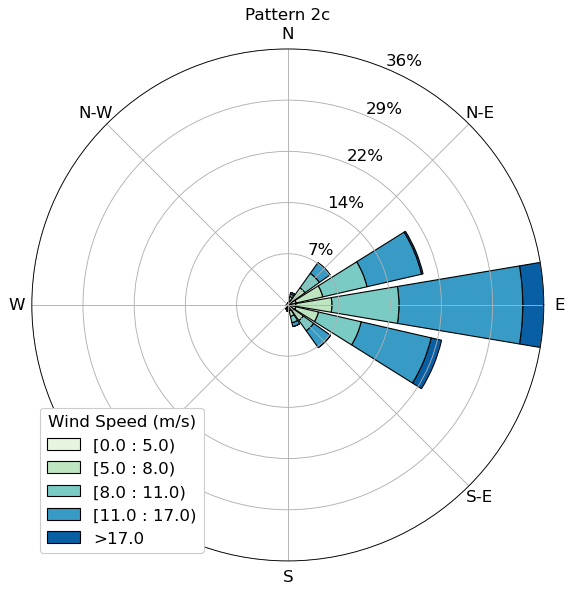

In [207]:
# legend
n = 0
# data to plot
ws = ws_all_0
wd = wd_all_0

fout = 'fig_5_windrose_legend'
print(fout)

title_str = 'Pattern '+som_nodes[s]

# Magically rounds the triangles (triangles to pizza slices if you will)
plt.hist([0, 1])
plt.close()

# Plot wind rose
ax = WindroseAxes.from_ax()
ax.bar(wd, ws, bins = windRange, normed=True, opening=0.85, linewidth=1, edgecolor='black', cmap=cmap)
ax.legend(title='Wind Speed (m/s)',title_fontsize=15, loc='lower left',fontsize=15,framealpha=1)
ax.set_title(title_str, fontsize = 15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# Format radius axis to percentages
fmt = '%.0f%%' 
yticks = mtick.FormatStrFormatter(fmt)
ax.yaxis.set_major_formatter(yticks)

#plt.show()
# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

fig_5_som_alaska_Nome_node_2c_windrose


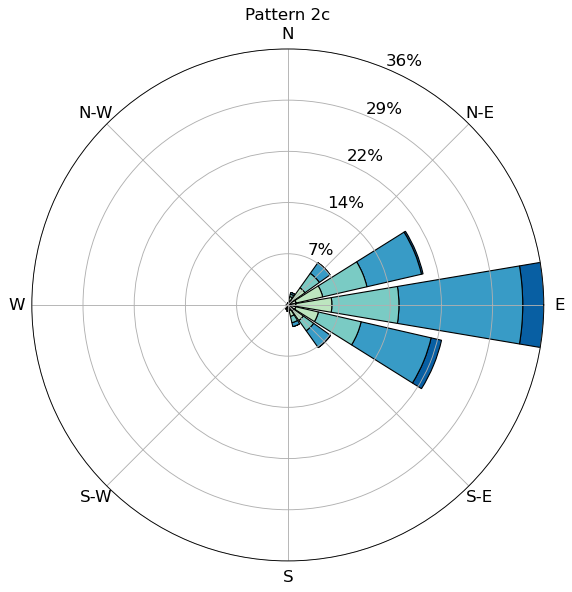

In [208]:
# village 1
n = 0
# data to plot
ws = ws_all_0
wd = wd_all_0

fout = 'fig_5_som_alaska_'+village_names[n]+'_node_'+som_nodes[s]+'_windrose'
print(fout)

title_str = 'Pattern '+som_nodes[s]

# Magically rounds the triangles (triangles to pizza slices if you will)
plt.hist([0, 1])
plt.close()

# Plot wind rose
ax = WindroseAxes.from_ax()
ax.bar(wd, ws, bins = windRange, normed=True, opening=0.85, linewidth=1, edgecolor='black', cmap=cmap)
#ax.legend(title='Wind Speed (m/s)',title_fontsize=15, loc='upper left',fontsize=15,framealpha=1)
ax.set_title(title_str, fontsize = 15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# Format radius axis to percentages
fmt = '%.0f%%' 
yticks = mtick.FormatStrFormatter(fmt)
ax.yaxis.set_major_formatter(yticks)

#plt.show()
# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

fig_5_som_alaska_Savoonga_node_2c_windrose


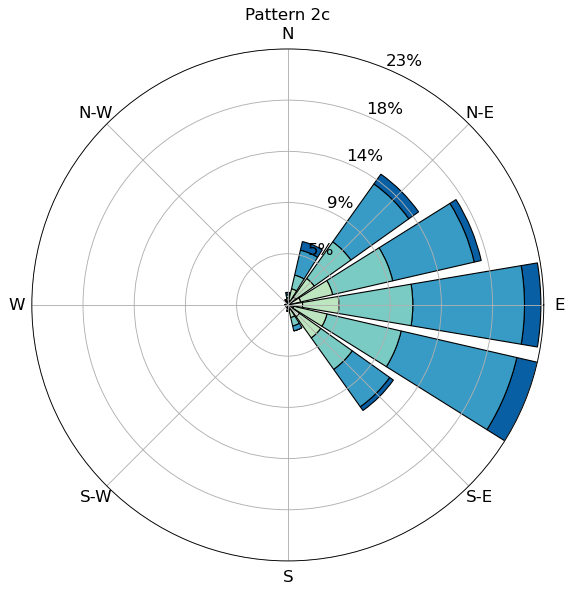

In [209]:
# village 2
n = 1
# data to plot
ws = ws_all_1
wd = wd_all_1

fout = 'fig_5_som_alaska_'+village_names[n]+'_node_'+som_nodes[s]+'_windrose'
print(fout)

title_str = 'Pattern '+som_nodes[s]

# Magically rounds the triangles (triangles to pizza slices if you will)
plt.hist([0, 1])
plt.close()

# Plot wind rose
ax = WindroseAxes.from_ax()
ax.bar(wd, ws, bins = windRange, normed=True, opening=0.85, linewidth=1, edgecolor='black', cmap=cmap)
#ax.legend(title='Wind Speed (m/s)',title_fontsize=15, loc='upper left',fontsize=15,framealpha=1)
ax.set_title(title_str, fontsize = 15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# Format radius axis to percentages
fmt = '%.0f%%' 
yticks = mtick.FormatStrFormatter(fmt)
ax.yaxis.set_major_formatter(yticks)

#plt.show()
# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

fig_5_som_alaska_Shishmaref_node_2c_windrose


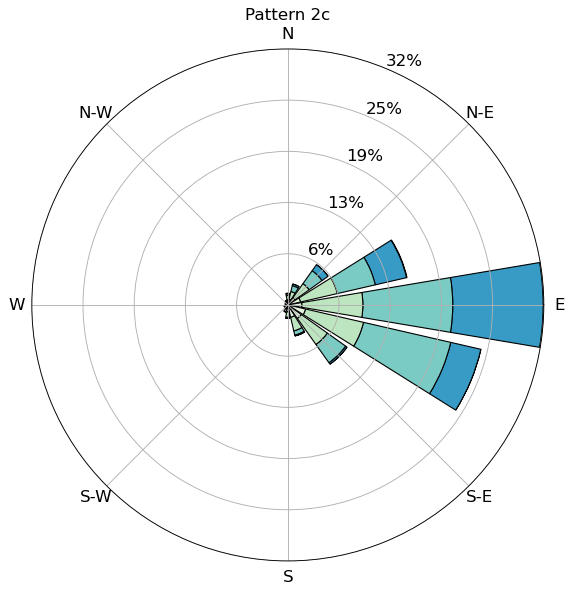

In [210]:
# village 3
n = 2
# data to plot
ws = ws_all_2
wd = wd_all_2

fout = 'fig_5_som_alaska_'+village_names[n]+'_node_'+som_nodes[s]+'_windrose'
print(fout)

title_str = 'Pattern '+som_nodes[s]

# Magically rounds the triangles (triangles to pizza slices if you will)
plt.hist([0, 1])
plt.close()

# Plot wind rose
ax = WindroseAxes.from_ax()
ax.bar(wd, ws, bins = windRange, normed=True, opening=0.85, linewidth=1, edgecolor='black', cmap=cmap)
#ax.legend(title='Wind Speed (m/s)',title_fontsize=15, loc='upper left',fontsize=15,framealpha=1)
ax.set_title(title_str, fontsize = 15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# Format radius axis to percentages
fmt = '%.0f%%' 
yticks = mtick.FormatStrFormatter(fmt)
ax.yaxis.set_major_formatter(yticks)

#plt.show()
# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

fig_5_som_alaska_Unalakleet_node_2c_windrose


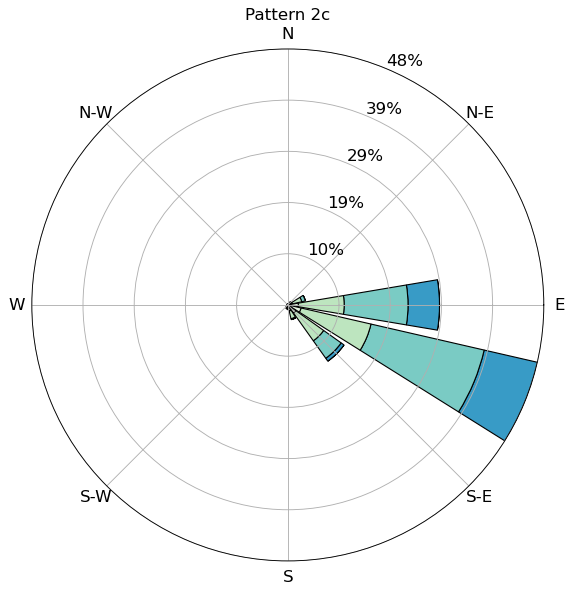

In [211]:
# village 4
n = 3
# data to plot
ws = ws_all_3
wd = wd_all_3

fout = 'fig_5_som_alaska_'+village_names[n]+'_node_'+som_nodes[s]+'_windrose'
print(fout)

title_str = 'Pattern '+som_nodes[s]

# Magically rounds the triangles (triangles to pizza slices if you will)
plt.hist([0, 1])
plt.close()

# Plot wind rose
ax = WindroseAxes.from_ax()
ax.bar(wd, ws, bins = windRange, normed=True, opening=0.85, linewidth=1, edgecolor='black', cmap=cmap)
#ax.legend(title='Wind Speed (m/s)',title_fontsize=15, loc='upper left',fontsize=15,framealpha=1)
ax.set_title(title_str, fontsize = 15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# Format radius axis to percentages
fmt = '%.0f%%' 
yticks = mtick.FormatStrFormatter(fmt)
ax.yaxis.set_major_formatter(yticks)

#plt.show()
# Finalize figure and save
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)